# Data Exploration: Interest Rate Analysis

This notebook demonstrates the data loading, validation, and exploration capabilities of the HJM-Vasicek modeling system.

## Overview

In this notebook, we will:
1. Load historical interest rate data from a CSV file
2. Validate the data quality
3. Compute summary statistics
4. Visualize yield curves and the yield surface
5. Analyze correlations across maturities


In [1]:
# Standard imports
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Add src to path if not installed
sys.path.insert(0, str(Path.cwd().parent))

# Project imports
from src.data.loader import load_interest_rate_data
from src.data.validator import validate_dataset
from src.analysis.statistics import compute_summary_statistics, compute_correlation_matrix
from src.visualization.yield_curves import plot_yield_curves, plot_yield_surface, plot_rate_time_series

# Set plot style
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11


## 1. Load Interest Rate Data

We'll load the sample Treasury rates data that contains 1 year of daily observations across 7 maturities (3M, 6M, 1Y, 2Y, 5Y, 10Y, 30Y).


In [2]:
# Load the sample data
data_path = Path.cwd().parent / "data" / "sample_treasury_rates.csv"

dataset = load_interest_rate_data(
    data_path,
    source_name="Sample Treasury Rates"
)

print(f"Dataset Summary:")
print(f"  Source: {dataset.source_name}")
print(f"  Observations: {dataset.n_observations}")
print(f"  Maturities: {dataset.n_maturities}")
print(f"  Date range: {dataset.date_range[0]} to {dataset.date_range[1]}")
print(f"  Maturities (years): {dataset.maturities}")


2026-01-11 22:13:22 | INFO     | hjm_vasicek.data.loader | Loading interest rate data from /home/haydar/personal/act/data/sample_treasury_rates.csv
2026-01-11 22:13:22 | INFO     | hjm_vasicek.data.loader | Loaded 252 observations with 7 maturities from Sample Treasury Rates
Dataset Summary:
  Source: Sample Treasury Rates
  Observations: 252
  Maturities: 7
  Date range: 2024-01-02 to 2024-12-18
  Maturities (years): [ 0.25  0.5   1.    2.    5.   10.   30.  ]


## 2. Validate Data Quality

Let's validate the dataset to ensure it meets our quality standards.


In [3]:
# Validate the dataset
report = validate_dataset(dataset)

print(f"Validation Report:")
print(f"  Valid: {report.is_valid}")
print(f"  Warnings: {len(report.warnings)}")
print(f"  Errors: {len(report.errors)}")

if report.warnings:
    print("\nWarnings:")
    for w in report.warnings:
        print(f"  - {w}")


2026-01-11 22:13:22 | INFO     | hjm_vasicek.data.validator | Validating dataset with 252 observations
2026-01-11 22:13:22 | INFO     | hjm_vasicek.data.validator | Validation passed with 0 warnings
Validation Report:
  Valid: True
  Warnings: 0
  Errors: 0


## 3. Summary Statistics

Compute descriptive statistics for each maturity.


In [4]:
# Compute summary statistics
stats = compute_summary_statistics(dataset)

# Display as a nice table
stats_df = stats.to_dataframe()
stats_df['mean_pct'] = stats_df['mean'] * 100
stats_df['std_pct'] = stats_df['std'] * 100
stats_df['min_pct'] = stats_df['min'] * 100
stats_df['max_pct'] = stats_df['max'] * 100

print("Summary Statistics (in percentage points):")
display_df = stats_df[['mean_pct', 'std_pct', 'min_pct', 'max_pct']].copy()
display_df.columns = ['Mean (%)', 'Std Dev (%)', 'Min (%)', 'Max (%)']
display_df.index.name = 'Maturity (Y)'
print(display_df.round(4).to_string())


2026-01-11 22:13:22 | INFO     | hjm_vasicek.analysis.statistics | Computing summary statistics for 252 observations across 7 maturities
Summary Statistics (in percentage points):
              Mean (%)  Std Dev (%)  Min (%)  Max (%)
Maturity (Y)                                         
0.25            5.4096       0.1888   4.9395   5.7962
0.50            5.5148       0.1539   5.1050   5.8361
1.00            4.8947       0.1868   4.4673   5.3117
2.00            4.6268       0.2192   4.1916   4.9971
5.00            4.2985       0.2086   3.8860   4.6574
10.00           4.3459       0.1737   4.0074   4.8163
30.00           4.6129       0.2088   4.2529   5.0568


## 4. Visualize Yield Curves

Let's plot yield curves for several selected dates to see the term structure.


2026-01-11 22:13:22 | INFO     | hjm_vasicek.visualization.yield_curves | Plotting 5 yield curves


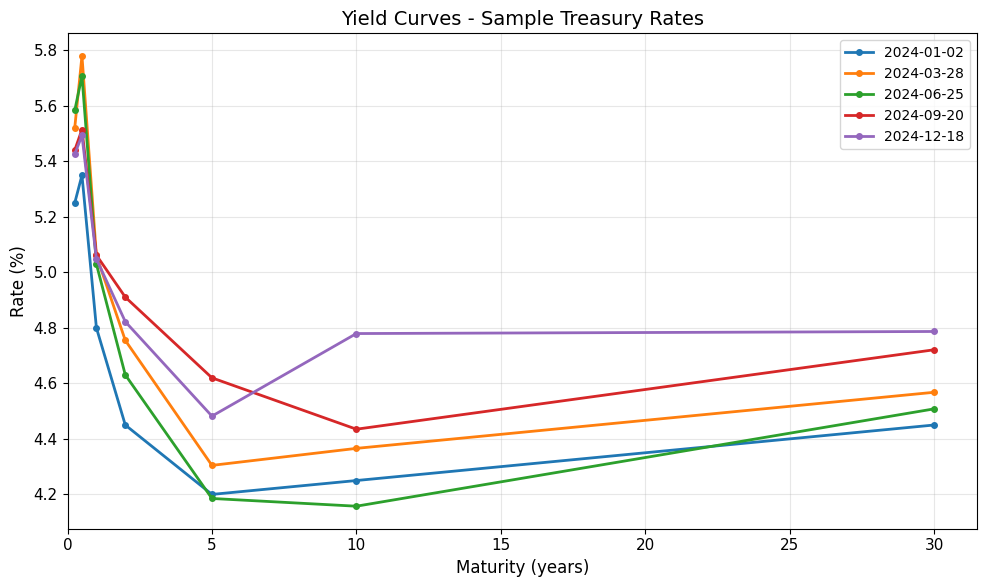

In [5]:
# Plot yield curves for 5 evenly spaced dates
fig = plot_yield_curves(dataset, n_curves=5)
plt.show()


## 5. Rate Time Series

Visualize how rates evolve over time for different maturities.


2026-01-11 22:13:22 | INFO     | hjm_vasicek.visualization.yield_curves | Plotting time series for 4 maturities


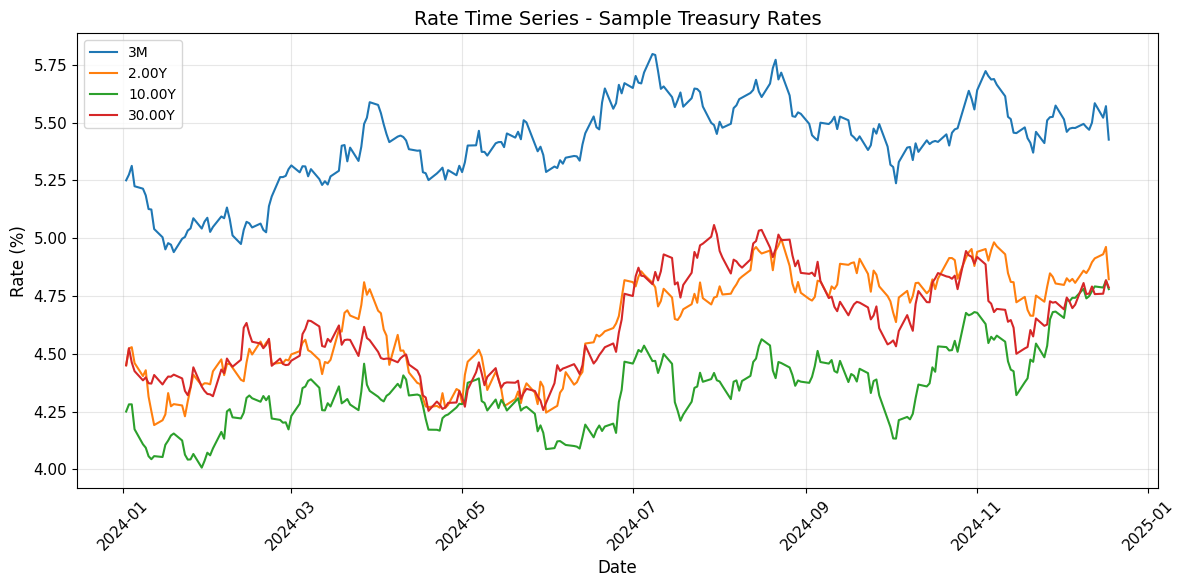

In [6]:
# Plot time series for selected maturities
fig = plot_rate_time_series(dataset, maturities=[0.25, 2.0, 10.0, 30.0])
plt.show()


## 6. Yield Surface (3D)

A 3D view of how the entire yield curve evolves over time.


2026-01-11 22:13:22 | INFO     | hjm_vasicek.visualization.yield_curves | Plotting yield surface for 252 observations


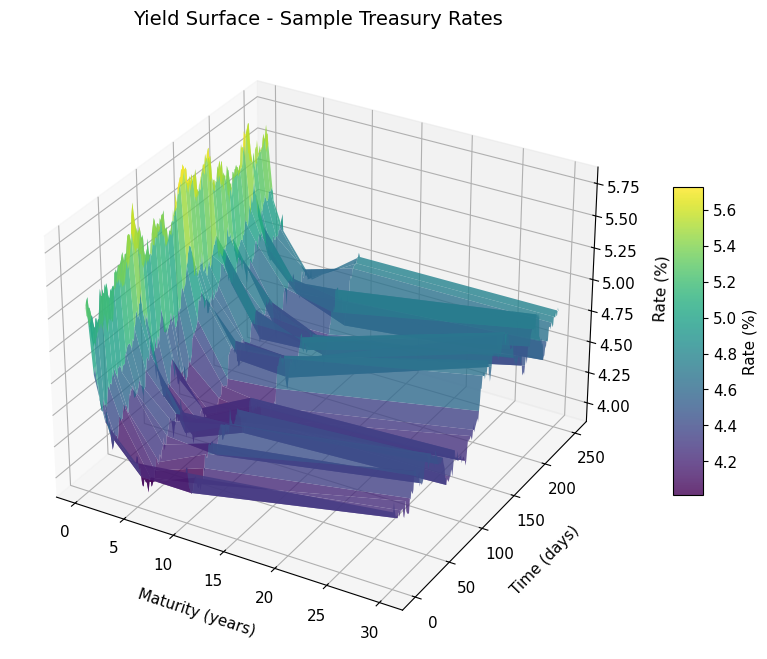

In [7]:
# Plot 3D yield surface
fig = plot_yield_surface(dataset)
plt.show()


## 7. Correlation Analysis

Analyze correlations between different maturities. We expect nearby maturities to be more highly correlated than distant ones.


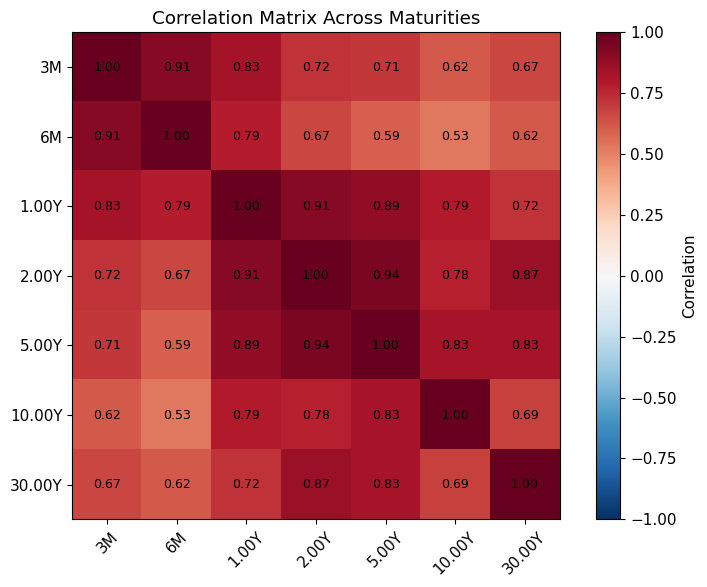

In [8]:
# Compute and visualize correlation matrix
corr_matrix = compute_correlation_matrix(dataset)

fig, ax = plt.subplots(figsize=(8, 6))

# Create heatmap
im = ax.imshow(corr_matrix, cmap='RdBu_r', vmin=-1, vmax=1)

# Add labels
maturity_labels = [f"{m:.2f}Y" if m >= 1 else f"{int(m*12)}M" for m in dataset.maturities]
ax.set_xticks(range(len(maturity_labels)))
ax.set_yticks(range(len(maturity_labels)))
ax.set_xticklabels(maturity_labels, rotation=45)
ax.set_yticklabels(maturity_labels)

# Add correlation values
for i in range(len(maturity_labels)):
    for j in range(len(maturity_labels)):
        ax.text(j, i, f"{corr_matrix[i, j]:.2f}",
                ha="center", va="center", color="black", fontsize=9)

ax.set_title("Correlation Matrix Across Maturities")
fig.colorbar(im, ax=ax, label="Correlation")
plt.tight_layout()
plt.show()


## Summary

In this notebook, we demonstrated:

1. **Data Loading**: Loading interest rate data from CSV files with automatic maturity parsing
2. **Validation**: Checking data quality including missing values, bounds, and chronological order
3. **Statistics**: Computing summary statistics (mean, std, min, max) for each maturity
4. **Visualization**: Creating yield curve plots, time series, and 3D surfaces
5. **Correlation**: Analyzing how different maturities move together

Key observations from the data:
- The term structure shows typical patterns (inverted, normal, or humped depending on the period)
- Nearby maturities are more highly correlated than distant ones
- Rate volatility varies across maturities

Next steps: Use this data for Vasicek model calibration (Notebook 02) and PCA analysis (Notebook 03).
